In [2]:
import numpy as np
import pandas as pd
import joblib
import shap
import matplotlib.pyplot as plt

X_test = np.load('../data/processed/X_test.npy')
y_test = np.load('../data/processed/y_test.npy')

label_encoder = joblib.load('../models/label_encoder.pkl')
feature_names = joblib.load('../models/feature_names.pkl')
class_names = label_encoder.classes_

model = joblib.load('../models/random_forest_model.pkl')

X_test_df = pd.DataFrame(X_test, columns=feature_names)

print("Model loaded:", type(model))
print(X_test_df.shape)

Model loaded: <class 'sklearn.ensemble._forest.RandomForestClassifier'>
(504160, 77)


In [3]:
X_sample = X_test_df.sample(n=2000, random_state=42)
y_sample_idx = X_sample.index

print("Sample shape:", X_sample.shape)

Sample shape: (2000, 77)


In [4]:
explainer = shap.TreeExplainer(model)
shap_values = explainer.shap_values(X_sample)

print(type(shap_values))
if isinstance(shap_values, list):
    print("Number of classes:", len(shap_values))
    print("Shape per class:", shap_values[0].shape)
else:
    print("Shape:", shap_values.shape)

<class 'numpy.ndarray'>
Shape: (2000, 77, 5)


Explaining class: Normal


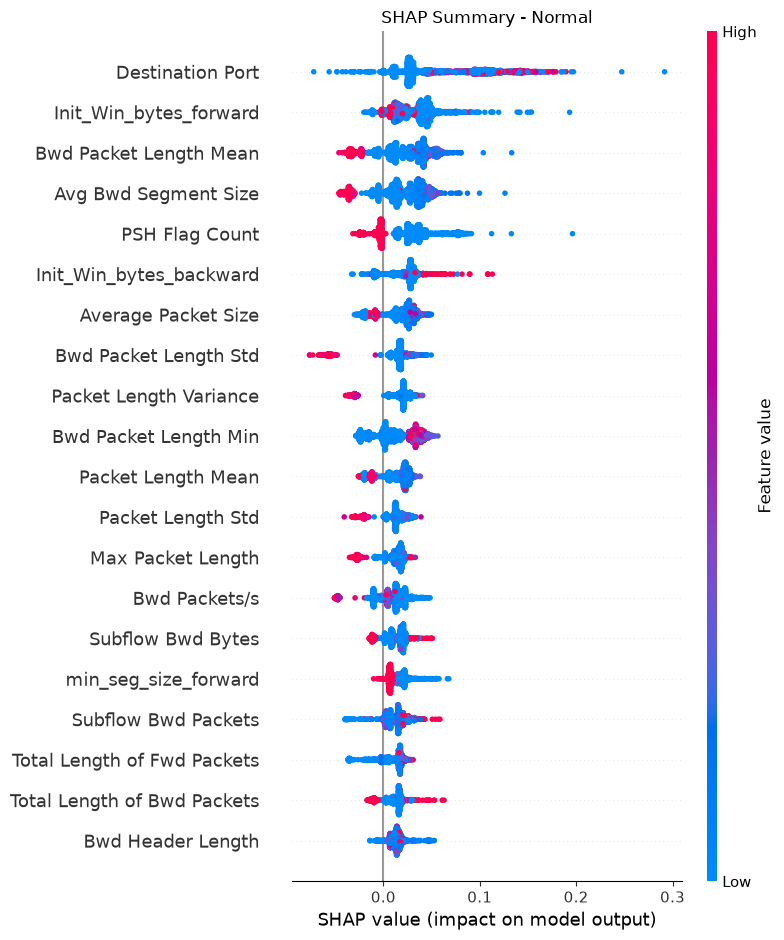

In [5]:
class_idx = 1
print(f"Explaining class: {class_names[class_idx]}")

plt.figure()
shap.summary_plot(shap_values[:, :, class_idx], X_sample, show=False)
plt.title(f"SHAP Summary - {class_names[class_idx]}")
plt.tight_layout()
plt.savefig(f'../reports/figures/shap_summary_{class_names[class_idx]}.png', bbox_inches='tight')
plt.show()

Explaining class: DoS


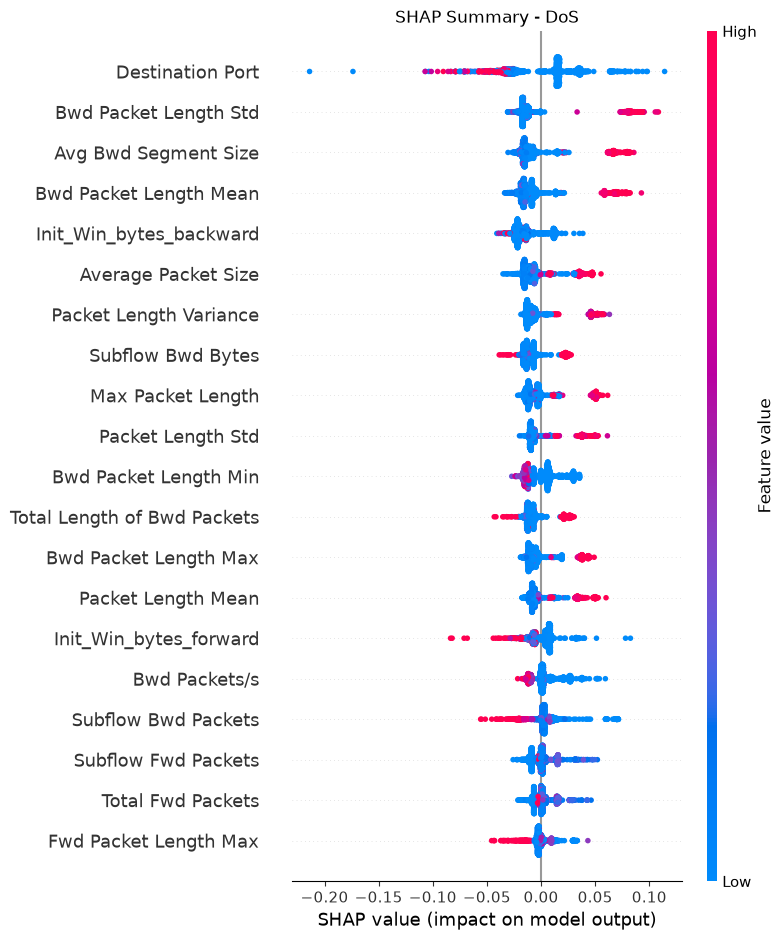

In [6]:
class_idx = 0
print(f"Explaining class: {class_names[class_idx]}")

plt.figure()
shap.summary_plot(shap_values[:, :, class_idx], X_sample, show=False)
plt.title(f"SHAP Summary - {class_names[class_idx]}")
plt.tight_layout()
plt.savefig(f'../reports/figures/shap_summary_{class_names[class_idx]}.png', bbox_inches='tight')
plt.show()

Explaining class: Probe


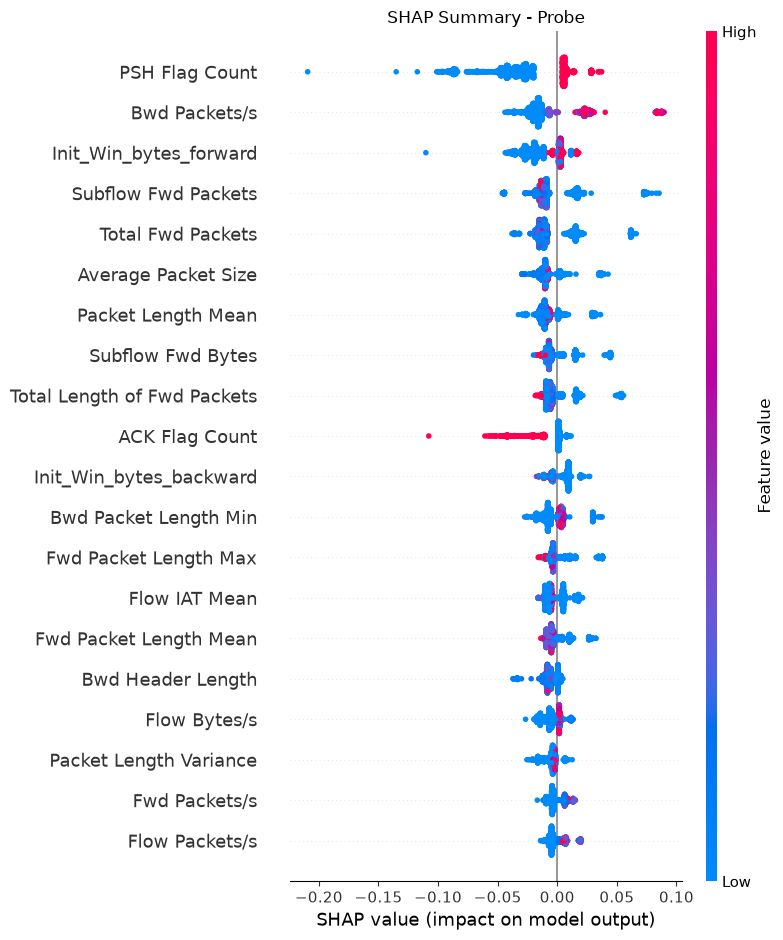

In [7]:
class_idx = 2
print(f"Explaining class: {class_names[class_idx]}")

plt.figure()
shap.summary_plot(shap_values[:, :, class_idx], X_sample, show=False)
plt.title(f"SHAP Summary - {class_names[class_idx]}")
plt.tight_layout()
plt.savefig(f'../reports/figures/shap_summary_{class_names[class_idx]}.png', bbox_inches='tight')
plt.show()

Explaining class: R2L


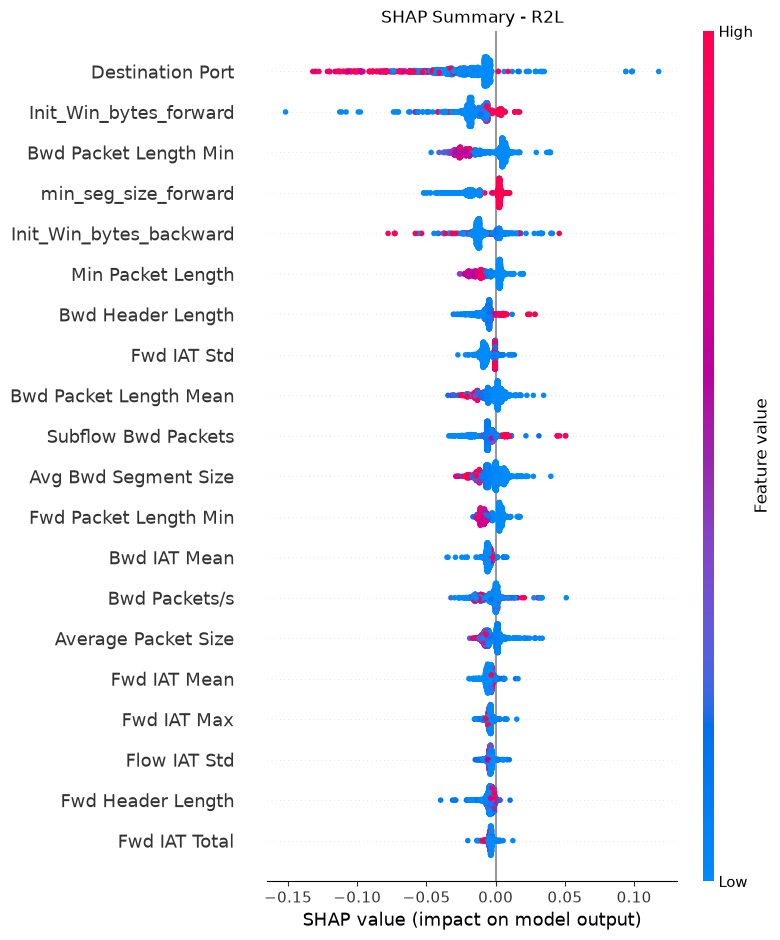

In [8]:
class_idx = 3
print(f"Explaining class: {class_names[class_idx]}")

plt.figure()
shap.summary_plot(shap_values[:, :, class_idx], X_sample, show=False)
plt.title(f"SHAP Summary - {class_names[class_idx]}")
plt.tight_layout()
plt.savefig(f'../reports/figures/shap_summary_{class_names[class_idx]}.png', bbox_inches='tight')
plt.show()

Explaining class: U2R


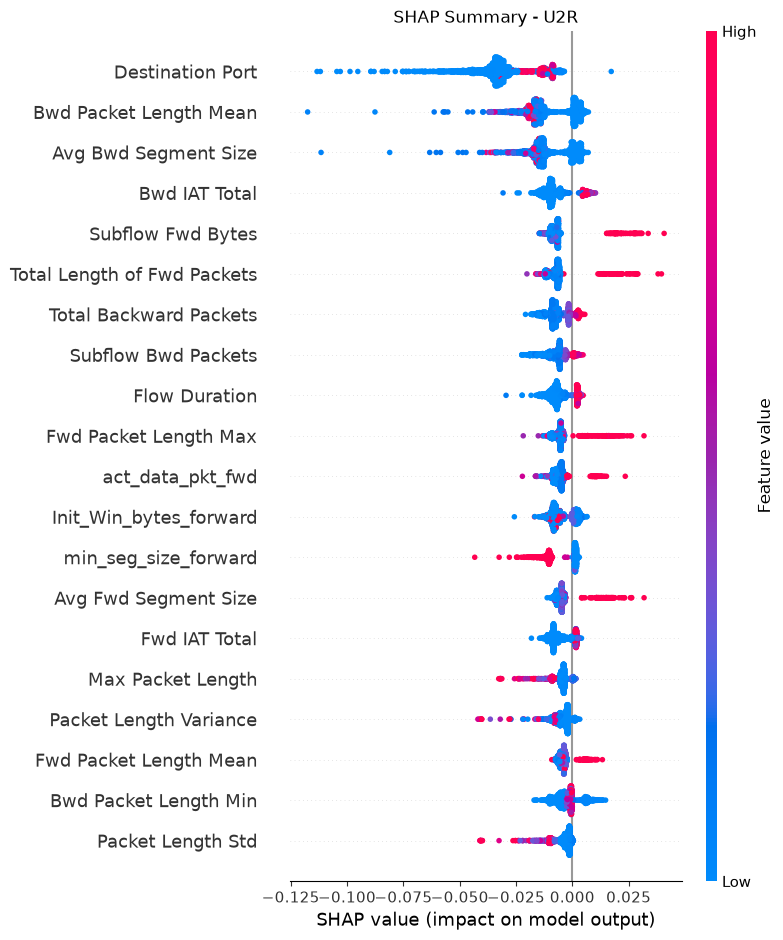

In [9]:
class_idx = 4
print(f"Explaining class: {class_names[class_idx]}")

plt.figure()
shap.summary_plot(shap_values[:, :, class_idx], X_sample, show=False)
plt.title(f"SHAP Summary - {class_names[class_idx]}")
plt.tight_layout()
plt.savefig(f'../reports/figures/shap_summary_{class_names[class_idx]}.png', bbox_inches='tight')
plt.show()

c:\Users\Nandini\Desktop\python\AI-ML-project\venv\Lib\site-packages\sklearn\utils\validation.py:2820: UserWarning: X has feature names, but RandomForestClassifier was fitted without feature names
  warnings.warn(


Model predicted: Normal


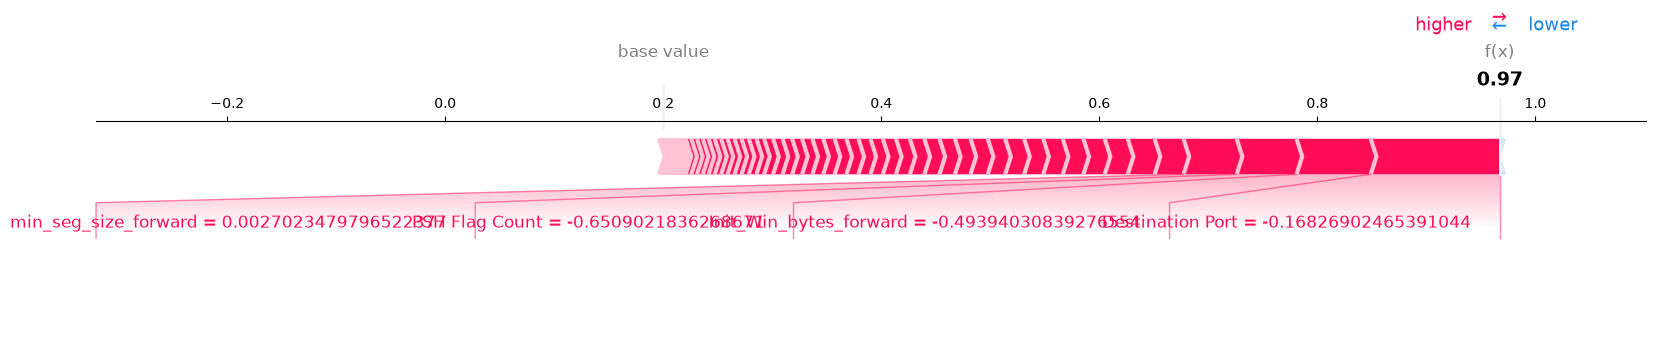

In [10]:
row_idx = 0
single_instance = X_sample.iloc[[row_idx]]

pred_class_idx = model.predict(single_instance)[0]
pred_class_name = class_names[pred_class_idx]
print(f"Model predicted: {pred_class_name}")

shap.initjs()

shap.force_plot(
    explainer.expected_value[pred_class_idx],
    shap_values[row_idx, :, pred_class_idx],
    single_instance,
    matplotlib=True, show=False
)

plt.savefig(f'../reports/figures/shap_force_plot_sample_{row_idx}.png', bbox_inches='tight')
plt.show()

                    feature  shap_value
0          Destination Port    0.118348
65   Init_Win_bytes_forward    0.068057
46           PSH Flag Count    0.054890
68     min_seg_size_forward    0.048778
47           ACK Flag Count    0.026484
42   Packet Length Variance    0.024671
34        Fwd Header Length    0.021115
41        Packet Length Std    0.019553
66  Init_Win_bytes_backward    0.018961
14             Flow Bytes/s    0.017916


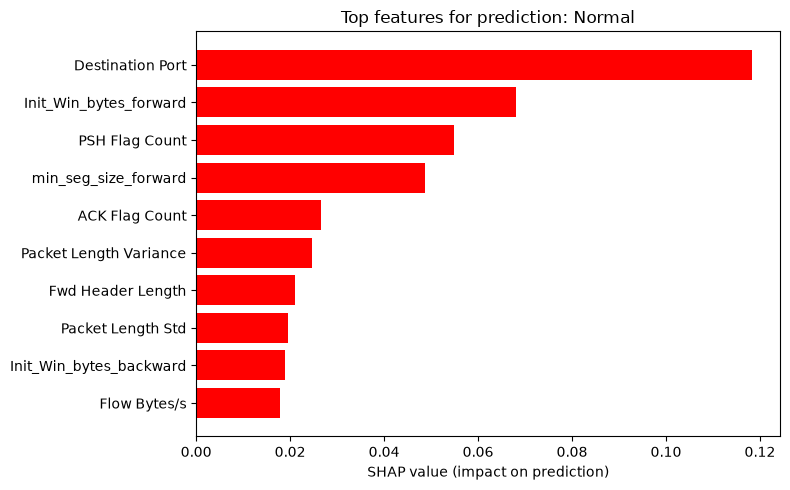

In [11]:
def get_top_shap_features(row_idx, pred_class_idx, top_n=10):
    row_shap = shap_values[row_idx, :, pred_class_idx]

    shap_df = pd.DataFrame({
        'feature': feature_names,
        'shap_value': row_shap
    })
    shap_df['abs_value'] = shap_df['shap_value'].abs()
    top_features = shap_df.sort_values('abs_value', ascending=False).head(top_n)
    return top_features[['feature', 'shap_value']]

top_features = get_top_shap_features(row_idx=0, pred_class_idx=pred_class_idx)
print(top_features)

plt.figure(figsize=(8,5))
colors = ['red' if v > 0 else 'blue' for v in top_features['shap_value']]
plt.barh(top_features['feature'], top_features['shap_value'], color=colors)
plt.xlabel('SHAP value (impact on prediction)')
plt.title(f'Top features for prediction: {pred_class_name}')
plt.gca().invert_yaxis()
plt.tight_layout()
plt.savefig('../reports/figures/shap_top_features_bar.png')
plt.show()

In [12]:
joblib.dump(explainer, '../models/shap_explainer.pkl')
print("SHAP explainer saved.")

SHAP explainer saved.


In [13]:
sample_for_demo = X_test_df.sample(20, random_state=1)
sample_for_demo.to_csv('../app/sample_traffic.csv', index=False)
print("Sample traffic file saved for Streamlit app.")

Sample traffic file saved for Streamlit app.
